# C05 — Frozen Ghostbuster baseline on Original → FZ118 → FZ186 → NFZ

This begins the C05 Ghostbuster series.

**Goal.** Train one frozen Ghostbuster-style detector on the regular RAID **training split only**, then score the same fixed 54 intervention sources at:

1. Original AI
2. Post FZ118 (Step 4)
3. Post FZ186 (Step 8)
4. **NFZ** = post FZ301 Step 10

We report AUROC, mean/median AI-class probability, and the usual validation-calibrated TPR staircase.

### Fidelity to Verma et al. (2024)

We preserve the published/released Ghostbuster pipeline as closely as possible:

- four aligned token-level streams: unigram, Kneser--Ney trigram, weak neural LM 1, weak neural LM 2;
- the released Ghostbuster vector/scalar operators;
- **depth-3** structured feature search (2534 candidates, matching Appendix C);
- forward feature selection on the training data;
- the released seven manually designed features;
- train-set normalization;
- L2 logistic regression with `C=1`, wrapped in 5-fold sigmoid calibration as in the released training code;
- the released Brown-corpus trigram model/tokenizer whenever available.

The only unavoidable substitution is the two retired GPT-3 Completion models (`ada`, `davinci`). For new NFZ text they can no longer be rescored reproducibly. We therefore use two frozen, non-instruction-tuned GPT-style LMs with the **same GPT-2/R50K tokenization and 2048-token context**:

- `EleutherAI/gpt-neo-125M` as the `ada`-slot surrogate;
- `EleutherAI/gpt-neo-1.3B` as the `davinci`-slot surrogate.

Expression names retain Ghostbuster's original `ada-logprobs` / `davinci-logprobs` labels, while the run contract records the surrogate mapping. This is therefore a **Ghostbuster-method reproduction trained on RAID**, not the authors' original released classifier.

Paper: Verma et al., *Ghostbuster: Detecting Text Ghostwritten by Large Language Models*, NAACL 2024.


In [1]:
from pathlib import Path
import sys,subprocess,hashlib,json,gc
import numpy as np,pandas as pd,torch,dill as pickle,tiktoken,nltk
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer,AutoModelForCausalLM
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score,roc_curve,auc
from IPython.display import display

ROOT=Path.cwd().resolve()
if not (ROOT/"results").exists(): ROOT=ROOT.parent
assert (ROOT/"results").exists(),ROOT
TCR_ROOT=ROOT.parent
BASE=ROOT/"results/causal/C02d2_fz118_ghostbuster_raid"
OUT=ROOT/"results/causal/C05_Ghostbuster_RAID_fixed54"; OUT.mkdir(parents=True,exist_ok=True)
CACHE=OUT/"cache"; CACHE.mkdir(exist_ok=True)
FIG=ROOT/"figures"; FIG.mkdir(exist_ok=True)

SEED=20260914
MAX_TOKENS=2047
SEARCH_DEPTH=3
ADA_SURROGATE="EleutherAI/gpt-neo-125M"
DAVINCI_SURROGATE="EleutherAI/gpt-neo-1.3B"
OFFICIAL_GB_COMMIT="f60068d006b7dc617af90e7148118837e85d0555"
np.random.seed(SEED); torch.manual_seed(SEED)
print("ROOT:",ROOT)
print("TCR_ROOT:",TCR_ROOT)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
TCR_ROOT: /home/user/Downloads/TemporalContextResearch


In [2]:
# Locate a pinned copy of official Ghostbuster without modifying an existing TCR checkout.
def git_head(p):
    try: return subprocess.check_output(["git","-C",str(p),"rev-parse","HEAD"],text=True).strip()
    except: return None

candidates=[TCR_ROOT/"data/external/ghostbuster",ROOT/"data/external/ghostbuster",ROOT/"data/external/ghostbuster-code"]
GB_CODE=None
for p in candidates:
    if (p/"utils/symbolic.py").exists() and git_head(p)==OFFICIAL_GB_COMMIT:
        GB_CODE=p; break
if GB_CODE is None:
    GB_CODE=ROOT/"data/external/ghostbuster-code"
    if not (GB_CODE/".git").exists():
        GB_CODE.parent.mkdir(parents=True,exist_ok=True)
        subprocess.run(["git","clone","https://github.com/vivek3141/ghostbuster.git",str(GB_CODE)],check=True)
    subprocess.run(["git","-C",str(GB_CODE),"fetch","origin",OFFICIAL_GB_COMMIT],check=True)
    subprocess.run(["git","-C",str(GB_CODE),"checkout","--detach",OFFICIAL_GB_COMMIT],check=True)
assert git_head(GB_CODE)==OFFICIAL_GB_COMMIT
sys.path.insert(0,str(GB_CODE))
from utils.symbolic import backtrack_functions,vec_functions,scalar_functions,get_words
from utils.featurize import t_featurize_logprobs,score_ngram,normalize,select_features
print("Ghostbuster code:",GB_CODE)
print("Commit:",git_head(GB_CODE))

ALL_EXPRESSIONS=backtrack_functions(max_depth=SEARCH_DEPTH)
assert len(ALL_EXPRESSIONS)==2534,len(ALL_EXPRESSIONS)
print("Depth-3 symbolic candidates:",len(ALL_EXPRESSIONS))


Ghostbuster code: ../data/external/ghostbuster-code
Commit: f60068d006b7dc617af90e7148118837e85d0555
Depth-3 symbolic candidates: 2534


In [3]:
# Load regular RAID + canonical fixed-54 stages.
STEP4=ROOT/"results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv"
STEP8=ROOT/"results/causal/C03e_lexical_micro_substitution/60d5986e77d8/texts_after_lexical_scored.csv"
STEP10_ROOT=ROOT/"results/causal/C04c_CARDINAL_controlled_insertion"

runs=[]
for p in sorted(STEP10_ROOT.glob("*")):
    s=p/"stage_summary.csv"; t=p/"texts_after_CARDINAL_step10.csv"
    if not s.exists() or not t.exists(): continue
    q=pd.read_csv(s); last=q.iloc[-1]
    if np.isclose(float(last.AUROC),.671326,atol=5e-6) and np.isclose(float(last.mean_AI_score),.476821,atol=5e-6): runs.append(p)
assert len(runs)==1,runs
STEP10_RUN=runs[0]

features_all=pd.read_parquet(BASE/"fz118_paired_features.parquet")
corpus=pd.read_parquet(BASE/"paired_corpus.parquet")
assert corpus.source_id.is_unique and features_all.source_id.is_unique
text_map=corpus.set_index("source_id").text.to_dict()

raid=features_all.loc[features_all.dataset.eq("raid"),["source_id","split","label","domain"]].copy().reset_index(drop=True)
raid["text"]=raid.source_id.map(text_map); assert raid.text.notna().all()
raid["doc_key"]="raid::"+raid.source_id.astype(str)

step4=pd.read_csv(STEP4,keep_default_na=False).sort_values("case_id").reset_index(drop=True)
step8=pd.read_csv(STEP8,keep_default_na=False).sort_values("case_id").reset_index(drop=True)
step10=pd.read_csv(STEP10_RUN/"texts_after_CARDINAL_step10.csv",keep_default_na=False).sort_values("case_id").reset_index(drop=True)
assert len(step4)==len(step8)==len(step10)==54
assert step4.case_id.tolist()==step8.case_id.tolist()==step10.case_id.tolist()
assert step4.source_id.tolist()==step8.source_id.tolist()==step10.source_id.tolist()

original=step10[["case_id","source_id","domain"]].copy(); original["text"]=original.source_id.map(text_map)
stages={"Original AI":original,"Post FZ118 (Step 4)":step4,"Post FZ186 (Step 8)":step8,"NFZ (Step 10)":step10}
for name,d in stages.items(): assert len(d)==54 and d.text.notna().all()
print("RAID rows:",len(raid),raid.split.value_counts().to_dict())
print("NFZ:",STEP10_RUN.relative_to(ROOT))


RAID rows: 1818 {'train': 1272, 'test': 276, 'validation': 270}
NFZ: results/causal/C04c_CARDINAL_controlled_insertion/16d25f12a76b


In [4]:
# One registry; deduplicate identical texts across stages by SHA256.
def sha_text(x): return hashlib.sha256(str(x).encode()).hexdigest()
docs=[raid[["doc_key","text"]].copy()]
for name,d in stages.items():
    z=d[["case_id","text"]].copy(); z["doc_key"]=name+"::"+z.case_id.astype(str)
    docs.append(z[["doc_key","text"]])
docs=pd.concat(docs,ignore_index=True); docs["text_sha"]=docs.text.map(sha_text)
unique_docs=docs.drop_duplicates("text_sha")[["text_sha","text"]].reset_index(drop=True)
raid["text_sha"]=raid.text.map(sha_text)
print("Registry rows:",len(docs),"unique texts requiring scoring:",len(unique_docs))


Registry rows: 2034 unique texts requiring scoring: 1954


## Token-probability streams

Ghostbuster's released pipeline uses the GPT-3 `davinci` tokenizer for all four streams. The Brown-corpus unigram/trigram models are defined over that same vocabulary. We preserve that tokenizer and load the released trigram model.

The two GPT-3 neural streams are replaced only because the retired models cannot score new NFZ documents. The replacements are required to use the same token IDs; the next cell asserts this before scoring.


In [5]:
# Tokenizer + released Brown-corpus n-gram model.
enc=tiktoken.encoding_for_model("davinci")
EOT=50256
trigram_path=GB_CODE/"model/trigram_model.pkl"
assert trigram_path.exists(),trigram_path
with trigram_path.open("rb") as f: trigram_model=pickle.load(f)
print("Loaded released trigram model:",trigram_path)

ada_tok=AutoTokenizer.from_pretrained(ADA_SURROGATE)
dav_tok=AutoTokenizer.from_pretrained(DAVINCI_SURROGATE)
for model_name,tok in [(ADA_SURROGATE,ada_tok),(DAVINCI_SURROGATE,dav_tok)]:
    for s in ["Hello world","A short test.\nSecond line."," can't won't 123"]:
        assert tok.encode(s,add_special_tokens=False)==enc.encode(s),(model_name,s)
print("✓ surrogate token IDs match Ghostbuster's tokenizer")


Loaded released trigram model: ../data/external/ghostbuster-code/model/trigram_model.pkl
✓ surrogate token IDs match Ghostbuster's tokenizer


In [6]:
# Cache neural token-probability streams. One document at a time is safe on an 8GB GPU.
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype=torch.float16 if device.type=="cuda" else torch.float32

def score_one(model,text):
    ids=enc.encode(str(text))[:MAX_TOKENS]
    if not ids: return np.array([],dtype=np.float32)
    x=torch.tensor([[EOT]+ids],device=device)
    with torch.inference_mode():
        logits=model(x).logits[0,:-1,:]
        target=x[0,1:]
        target_logits=logits.gather(1,target[:,None]).squeeze(1)
        p=torch.exp(target_logits-torch.logsumexp(logits,dim=-1)).float().cpu().numpy()
    return p.astype(np.float32)

def score_model_cache(model_name,cache_name):
    path=CACHE/f"{cache_name}.parquet"
    old=pd.read_parquet(path) if path.exists() else pd.DataFrame(columns=["text_sha","probs"])
    have=set(old.text_sha.astype(str))
    todo=unique_docs.loc[~unique_docs.text_sha.isin(have)]
    if len(todo):
        print("Loading",model_name,"; missing",len(todo))
        model=AutoModelForCausalLM.from_pretrained(model_name,torch_dtype=dtype,low_cpu_mem_usage=True).to(device).eval()
        rows=[]
        for r in tqdm(todo.itertuples(index=False),total=len(todo),desc=cache_name):
            rows.append({"text_sha":r.text_sha,"probs":score_one(model,r.text).tolist()})
            if len(rows)>=50:
                old=pd.concat([old,pd.DataFrame(rows)],ignore_index=True); old.to_parquet(path,index=False); rows=[]
        if rows: old=pd.concat([old,pd.DataFrame(rows)],ignore_index=True)
        old.drop_duplicates("text_sha",keep="last").to_parquet(path,index=False)
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.read_parquet(path).set_index("text_sha").probs.to_dict()

ada_map=score_model_cache(ADA_SURROGATE,"ada_surrogate_probs")
dav_map=score_model_cache(DAVINCI_SURROGATE,"davinci_surrogate_probs")
print("Cached neural streams:",len(ada_map),len(dav_map))


Cached neural streams: 1954 1954


In [7]:
# Brown unigram/trigram streams — direct Ghostbuster evaluation, avoiding old NLTK score_ngram path.
from utils.symbolic import train_trigram

# First verify the released pickle is functional; if not, rebuild the exact Brown model with official code.
try:
    _=trigram_model.n_gram_probability((EOT,EOT,enc.encode("test")[0]))
    print("✓ released trigram pickle is functional")
except Exception as e:
    print("Released trigram pickle incompatible:",repr(e))
    nltk.download("brown",quiet=True)
    trigram_model=train_trigram(verbose=True)
    print("✓ rebuilt Ghostbuster Brown trigram with official code")

def gb_ngram_streams(text):
    ids=enc.encode(str(text))[:MAX_TOKENS]
    pad=[EOT,EOT]+ids
    tri=np.asarray([trigram_model.n_gram_probability(tuple(pad[i:i+3])) for i in range(len(ids))],dtype=np.float32)
    uni=np.asarray([trigram_model.base.n_gram_probability((t,)) for t in ids],dtype=np.float32)
    return tri,uni

ngram_path=CACHE/"ngram_probs_v2.parquet"
ng=pd.read_parquet(ngram_path) if ngram_path.exists() else pd.DataFrame(columns=["text_sha","trigram","unigram"])
have=set(ng.text_sha.astype(str)); todo=unique_docs.loc[~unique_docs.text_sha.isin(have)]
rows=[]
for r in tqdm(todo.itertuples(index=False),total=len(todo),desc="Brown ngrams"):
    tri,uni=gb_ngram_streams(r.text)
    rows.append({"text_sha":r.text_sha,"trigram":tri.tolist(),"unigram":uni.tolist()})
    if len(rows)>=100:
        ng=pd.concat([ng,pd.DataFrame(rows)],ignore_index=True); ng.to_parquet(ngram_path,index=False); rows=[]
if rows: ng=pd.concat([ng,pd.DataFrame(rows)],ignore_index=True)
ng.drop_duplicates("text_sha",keep="last").to_parquet(ngram_path,index=False)
ng=pd.read_parquet(ngram_path).set_index("text_sha")
tri_map=ng.trigram.to_dict(); uni_map=ng.unigram.to_dict()

def streams(h):
    vm={"ada-logprobs":np.asarray(ada_map[h],float),"davinci-logprobs":np.asarray(dav_map[h],float),
        "trigram-logprobs":np.asarray(tri_map[h],float),"unigram-logprobs":np.asarray(uni_map[h],float)}
    n={k:len(v) for k,v in vm.items()}
    if len(set(n.values()))!=1: raise ValueError((h,n))
    return vm

for h in unique_docs.text_sha: streams(h)
print("✓ all four Ghostbuster streams aligned for",len(unique_docs),"unique texts")

Released trigram pickle incompatible: SystemError('error return without exception set')


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


Tokenizing corpus...


100%|██████████████████████████████████████████████████████████████████████████████████████████| 57340/57340 [00:02<00:00, 23326.69it/s]



Training n-gram model...


100%|█████████████████████████████████████████████████████████████████████████████████████| 1283104/1283104 [00:02<00:00, 499530.59it/s]


✓ rebuilt Ghostbuster Brown trigram with official code


Brown ngrams: 0it [00:00, ?it/s]

✓ all four Ghostbuster streams aligned for 1954 unique texts


In [8]:
# Ghostbuster symbolic matrix in float64 + released forward selection.
import warnings
warnings.filterwarnings("ignore",category=FutureWarning,module="sklearn")

def eval_expr(exp,vm):
    tok=get_words(exp); cur=vm[tok[0]]; i=1
    while i<len(tok):
        if tok[i] in vec_functions:
            cur=vec_functions[tok[i]](cur,vm[tok[i+1]]); i+=2
        elif tok[i] in scalar_functions:
            return float(scalar_functions[tok[i]](cur))
        else:
            raise KeyError(tok[i])
    raise RuntimeError(exp)

train=raid.loc[raid.split.eq("train")].reset_index(drop=True)
cand_path=CACHE/"symbolic_candidates_train_f64.npy"
names_path=CACHE/"symbolic_candidate_names_f64.json"

if cand_path.exists() and names_path.exists() and json.loads(names_path.read_text())==ALL_EXPRESSIONS:
    C=np.load(cand_path)
    assert C.shape==(len(train),len(ALL_EXPRESSIONS)) and C.dtype==np.float64
    print("Loaded float64 candidate matrix:",C.shape)
else:
    C=np.empty((len(train),len(ALL_EXPRESSIONS)),dtype=np.float64)
    for i,r in enumerate(tqdm(train.itertuples(index=False),total=len(train),desc="symbolic matrix")):
        vm=streams(r.text_sha)
        with np.errstate(over="ignore",divide="ignore",invalid="ignore"):
            for j,exp in enumerate(ALL_EXPRESSIONS):
                C[i,j]=eval_expr(exp,vm)
    np.save(cand_path,C); names_path.write_text(json.dumps(ALL_EXPRESSIONS,indent=2))
    print("Saved float64 candidate matrix:",C.shape)

finite=np.isfinite(C)
print("dtype:",C.dtype)
print("finite:",finite.sum(),"/",C.size)
print("nonfinite:",(~finite).sum())
print("max |feature|:",np.max(np.abs(C[finite])))

bad_cols=np.where(~np.isfinite(C).all(axis=0))[0]
if len(bad_cols):
    print("\nBad expressions:")
    for i in bad_cols[:20]: print(" •",ALL_EXPRESSIONS[i])
assert len(bad_cols)==0,f"{len(bad_cols)} symbolic expressions produced NaN/Inf"

exp_to_data={e:C[:,i:i+1] for i,e in enumerate(ALL_EXPRESSIONS)}
y_train=train.label.astype(int).to_numpy()
torch.manual_seed(SEED)

selected_path=OUT/"selected_features.txt"
if selected_path.exists(): selected_path.unlink()

selected=select_features(exp_to_data,y_train,verbose=True,to_normalize=True,indices=None)
selected_path.write_text("\n".join(selected)+"\n")

print("\nSelected",len(selected),"symbolic features")
for x in selected: print(" •",x)

symbolic matrix: 100%|██████████████████████████████████████████████████████████████████████████████| 1272/1272 [03:41<00:00,  5.75it/s]


Saved float64 candidate matrix: (1272, 2534)
dtype: float64
finite: 3223248 / 3223248
nonfinite: 0
max |feature|: 1.002830097663763e+28


100%|██████████████████████████████████████████████████████████████████████████████████████████████| 2534/2534 [00:23<00:00, 105.74it/s]


Iteration 0, Current Score: 0,                 Best Feature: unigram-logprobs v-sub davinci-logprobs s-avg-top-25, New Score: 0.8066190945


100%|███████████████████████████████████████████████████████████████████████████████████████████████| 2533/2533 [00:34<00:00, 72.49it/s]


...

Iteration 5, Current Score: 0.8671505906,                 Best Feature: davinci-logprobs v-div unigram-logprobs v-< ada-logprobs s-avg, New Score: 0.8711306594


100%|███████████████████████████████████████████████████████████████████████████████████████████████| 2528/2528 [00:46<00:00, 54.13it/s]


Iteration 6, Current Score: 0.8711306594,                 Best Feature: ada-logprobs v-> davinci-logprobs v-div trigram-logprobs s-avg-top-25, New Score: 0.8742372047


100%|███████████████████████████████████████████████████████████████████████████████████████████████| 2527/2527 [00:43<00:00, 57.72it/s]

Iteration 7, Current Score: 0.8742372047,                 Best Feature: unigram-logprobs v-add trigram-logprobs v-add ada-logprobs s-max, New Score: 0.8735113189

Selected 7 symbolic features
 • unigram-logprobs v-sub davinci-logprobs s-avg-top-25
 • unigram-logprobs v-> trigram-logprobs v-< ada-logprobs s-l2
 • trigram-logprobs v-add ada-logprobs v-sub davinci-logprobs s-avg
 • unigram-logprobs v-sub ada-logprobs v-div trigram-logprobs s-avg-top-25
 • unigram-logprobs v-< trigram-logprobs v-sub ada-logprobs s-avg-top-25
 • davinci-logprobs v-div unigram-logprobs v-< ada-logprobs s-avg
 • ada-logprobs v-> davinci-logprobs v-div trigram-logprobs s-avg-top-25


In [9]:
# Final Ghostbuster vector = released seven handcrafted features + selected symbolic features.
MANUAL_NAMES=["outlier_count","outlier_top25_mean","outlier_25_50_mean",
              "davinci_minus_ada_top25_mean","davinci_minus_ada_25_50_mean",
              "word_token_len_top25_mean","word_token_len_25_50_mean"]
FEATURE_NAMES=MANUAL_NAMES+selected

def ghostbuster_vector(text,h):
    vm=streams(h)
    ids=enc.encode(str(text))[:MAX_TOKENS]
    token_strings=ada_tok.convert_ids_to_tokens(ids)
    manual=list(map(float,t_featurize_logprobs(vm["davinci-logprobs"],vm["ada-logprobs"],token_strings)))
    symbolic=[eval_expr(e,vm) for e in selected]
    return np.asarray(manual+symbolic,dtype=float)

def feature_frame(df,label):
    cache=OUT/f"{label}_features.parquet"
    if cache.exists():
        z=pd.read_parquet(cache)
        if len(z)==len(df) and z.doc_key.tolist()==df.doc_key.tolist(): return z
    rows=[]
    for r in tqdm(df.itertuples(index=False),total=len(df),desc=label):
        v=ghostbuster_vector(r.text,r.text_sha)
        rows.append({"doc_key":r.doc_key,**dict(zip(FEATURE_NAMES,v))})
    z=pd.DataFrame(rows); z.to_parquet(cache,index=False); return z

train_f=feature_frame(train,"raid_train")
X_train_raw=train_f[FEATURE_NAMES].to_numpy(float)
X_train,mu,sigma=normalize(X_train_raw,ret_mu_sigma=True)

base=LogisticRegression(C=1.0,penalty="l2",max_iter=2000,random_state=SEED)
gb=CalibratedClassifierCV(base,cv=5,method="sigmoid")
gb.fit(X_train,y_train)
with (OUT/"ghostbuster_frozen.pkl").open("wb") as f: pickle.dump(gb,f)
np.save(OUT/"mu.npy",mu); np.save(OUT/"sigma.npy",sigma)
(OUT/"feature_names.json").write_text(json.dumps(FEATURE_NAMES,indent=2))
print("Frozen detector feature dim:",len(FEATURE_NAMES))


raid_train: 100%|██████████████████████████████████████████████████████████████████████████████████| 1272/1272 [00:02<00:00, 484.29it/s]

Frozen detector feature dim: 14


In [10]:
# Score all RAID rows + fixed-54 stages.
raid_eval=raid.copy()
raid_f=feature_frame(raid_eval,"raid_all")
raid_X=normalize(raid_f[FEATURE_NAMES].to_numpy(float),mu=mu,sigma=sigma)
raid_scores=gb.predict_proba(raid_X)[:,1]
raid_eval["AI_score"]=raid_scores

stage_scores={}; stage_tables={}
for name,d0 in stages.items():
    d=d0.copy(); d["doc_key"]=name+"::"+d.case_id.astype(str); d["text_sha"]=d.text.map(sha_text)
    key=name.lower().replace(" ","_").replace("(","").replace(")","")
    f=feature_frame(d,key)
    x=normalize(f[FEATURE_NAMES].to_numpy(float),mu=mu,sigma=sigma)
    s=gb.predict_proba(x)[:,1]; stage_scores[name]=s
    z=d[["case_id","source_id","domain"]].copy(); z["AI_score"]=s; stage_tables[name]=z

test=raid_eval.loc[raid_eval.split.eq("test")]
print("RAID test AUROC (sanity):",roc_auc_score(test.label,test.AI_score))


nfz_step_10: 100%|█████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:00<00:00, 544.61it/s]

RAID test AUROC (sanity): 0.9086326402016383


In [11]:
# Same fixed genre-weighted human calibration/test protocol used in the FZ series.
def masks_weights(domains):
    mix=pd.Series(domains).value_counts(normalize=True)
    def mask(split): return (raid_eval.split.eq(split)&raid_eval.label.eq(0)&raid_eval.domain.isin(mix.index)).to_numpy()
    def weights(m):
        g=raid_eval.loc[m,"domain"]; counts=g.value_counts()
        w=np.array([mix[x]/counts[x] for x in g],float); assert np.isclose(w.sum(),1); return w
    cm,hm=mask("validation"),mask("test"); return cm,hm,weights(cm),weights(hm)

def weighted_auc(hs,wh,ais):
    y=np.r_[np.zeros(len(hs)),np.ones(len(ais))]; s=np.r_[hs,ais]
    w=np.r_[wh,np.ones(len(ais))/len(ais)]
    fpr,tpr,_=roc_curve(y,s,sample_weight=w,drop_intermediate=False); return auc(fpr,tpr)

def staircase(cal,wc,hs,wh,series):
    cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf]
    d={"threshold":cuts,"calibration_FPR":[wc[cal>c].sum() for c in cuts],
       "test_FPR":[wh[hs>c].sum() for c in cuts]}
    for name,s in series.items(): d[name]=[(s>c).mean() for c in cuts]
    return pd.DataFrame(d)

cm,hm,wc,wh=masks_weights(step10.domain)
cal_scores=raid_eval.loc[cm,"AI_score"].to_numpy()
human_scores=raid_eval.loc[hm,"AI_score"].to_numpy()

summary=pd.DataFrame([{"stage":name,"AUROC":weighted_auc(human_scores,wh,s),
                       "mean_AI_score":s.mean(),"median_AI_score":np.median(s)}
                      for name,s in stage_scores.items()])
display(summary)
summary.to_csv(OUT/"stage_summary.csv",index=False)
for name,z in stage_tables.items():
    key=name.lower().replace(" ","_").replace("(","").replace(")","")
    z.to_csv(OUT/f"{key}_scores.csv",index=False)


,stage,AUROC,mean_AI_score,median_AI_score
0,Original AI,0.917333,0.738358,0.833199
1,Post FZ118 (Step 4),0.820165,0.568135,0.610294
2,Post FZ186 (Step 8),0.744837,0.465446,0.398728
3,NFZ (Step 10),0.717215,0.432177,0.346497


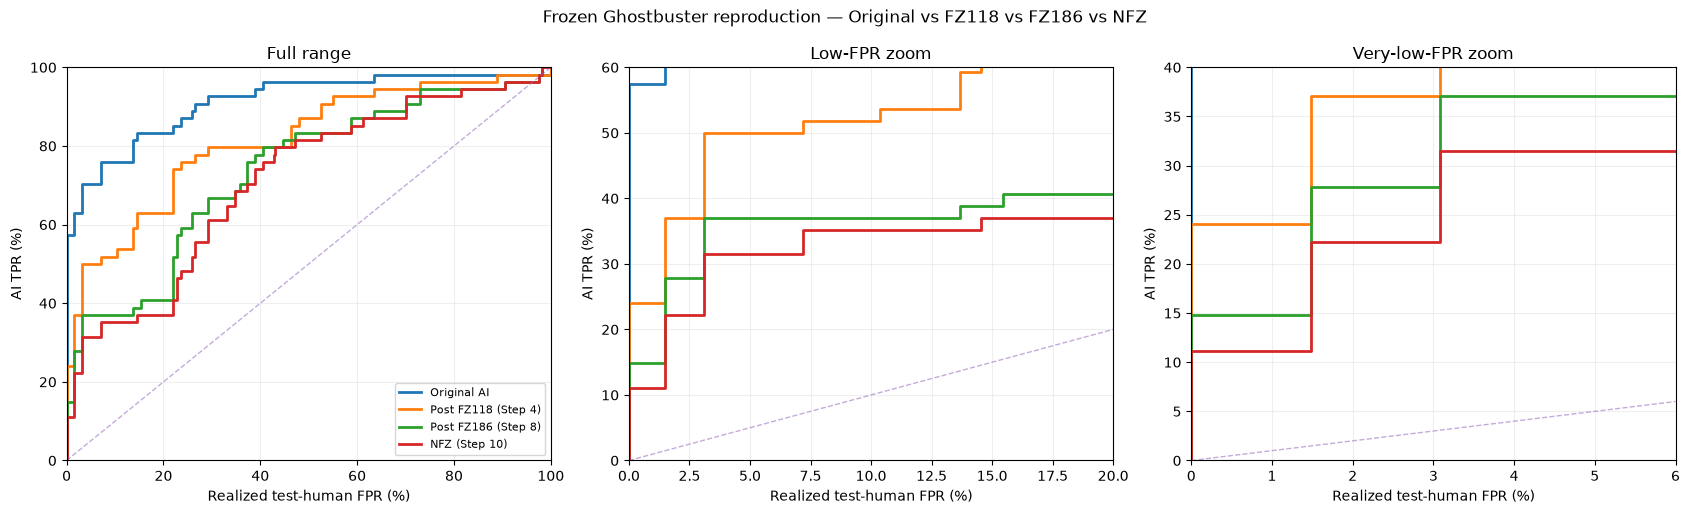

In [12]:
# TPR staircase: Original → Step 4 → Step 8 → NFZ.
st=staircase(cal_scores,wc,human_scores,wh,stage_scores)
st.to_csv(OUT/"C05_Ghostbuster_original_step4_step8_NFZ_TPR_staircase.csv",index=False)

fig,axs=plt.subplots(1,3,figsize=(17,5.2))
panels=[((0,100),(0,100),"Full range"),((0,20),(0,60),"Low-FPR zoom"),((0,6),(0,40),"Very-low-FPR zoom")]
for ax,(xlim,ylim,title) in zip(axs,panels):
    for name in stage_scores: ax.step(st.test_FPR*100,st[name]*100,where="post",lw=2,label=name)
    hi=min(xlim[1],ylim[1]); ax.plot([0,hi],[0,hi],"--",lw=1,alpha=.55)
    ax.set(xlim=xlim,ylim=ylim,xlabel="Realized test-human FPR (%)",ylabel="AI TPR (%)",title=title); ax.grid(alpha=.2)
axs[0].legend(loc="lower right",fontsize=8)
fig.suptitle("Frozen Ghostbuster reproduction — Original vs FZ118 vs FZ186 vs NFZ")
fig.tight_layout()
stem="C05_Ghostbuster_original_step4_step8_NFZ_TPR_staircase"
for folder in [OUT,FIG]:
    fig.savefig(folder/f"{stem}.pdf",bbox_inches="tight")
    fig.savefig(folder/f"{stem}.png",dpi=300,bbox_inches="tight")
plt.show()


In [13]:
# Save the frozen C05 contract for C05a+.
contract={
    "name":"C05_Ghostbuster_RAID_fixed54","seed":SEED,"training_data":"regular RAID train only",
    "fixed54_stages":["Original AI","Post FZ118 (Step 4)","Post FZ186 (Step 8)","NFZ (Step 10)"],
    "ghostbuster_paper":"Verma et al. 2024 NAACL, https://aclanthology.org/2024.naacl-long.95/",
    "official_code_commit":OFFICIAL_GB_COMMIT,"search_depth":SEARCH_DEPTH,
    "candidate_symbolic_features":len(ALL_EXPRESSIONS),"selected_symbolic_features":len(selected),
    "manual_features":MANUAL_NAMES,"max_tokens":MAX_TOKENS,
    "stream_mapping":{"unigram":"released Brown unigram fertility model",
                      "trigram":"released Brown Kneser-Ney trigram model",
                      "ada-logprobs":ADA_SURROGATE,"davinci-logprobs":DAVINCI_SURROGATE},
    "classifier":"CalibratedClassifierCV(LogisticRegression(C=1,L2), cv=5, sigmoid)",
    "normalization":"mu/sigma fit on RAID train only",
    "human_protocol":"same-genre mixture; validation-human thresholds; realized FPR on fixed test humans",
    "NFZ_input":str((STEP10_RUN/"texts_after_CARDINAL_step10.csv").relative_to(ROOT)),
    "note":"GPT-3 ada/davinci are retired; local non-instruction GPT-style surrogates are the only architectural substitution."
}
(OUT/"contract.json").write_text(json.dumps(contract,indent=2))
print("Saved C05 outputs to:",OUT.relative_to(ROOT))


Saved C05 outputs to: results/causal/C05_Ghostbuster_RAID_fixed54
